## Loading JSON data and reproducing contour plots
This notebook demonstrates how to load the JSON files containing the client and insurer VoI results and use them to reproduce the contour plots. The JSON files must be available in the same directory as the notebook, or the file paths must be adjusted accordingly.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Load the JSON files
with open('vs30_250_evpi_client_181224.json', 'r') as file:
    EVPI_matrix = np.array(json.load(file))

with open('vs30_250_evpi_ins_181224.json', 'r') as file:
    EVPI_profit_matrix = np.array(json.load(file))

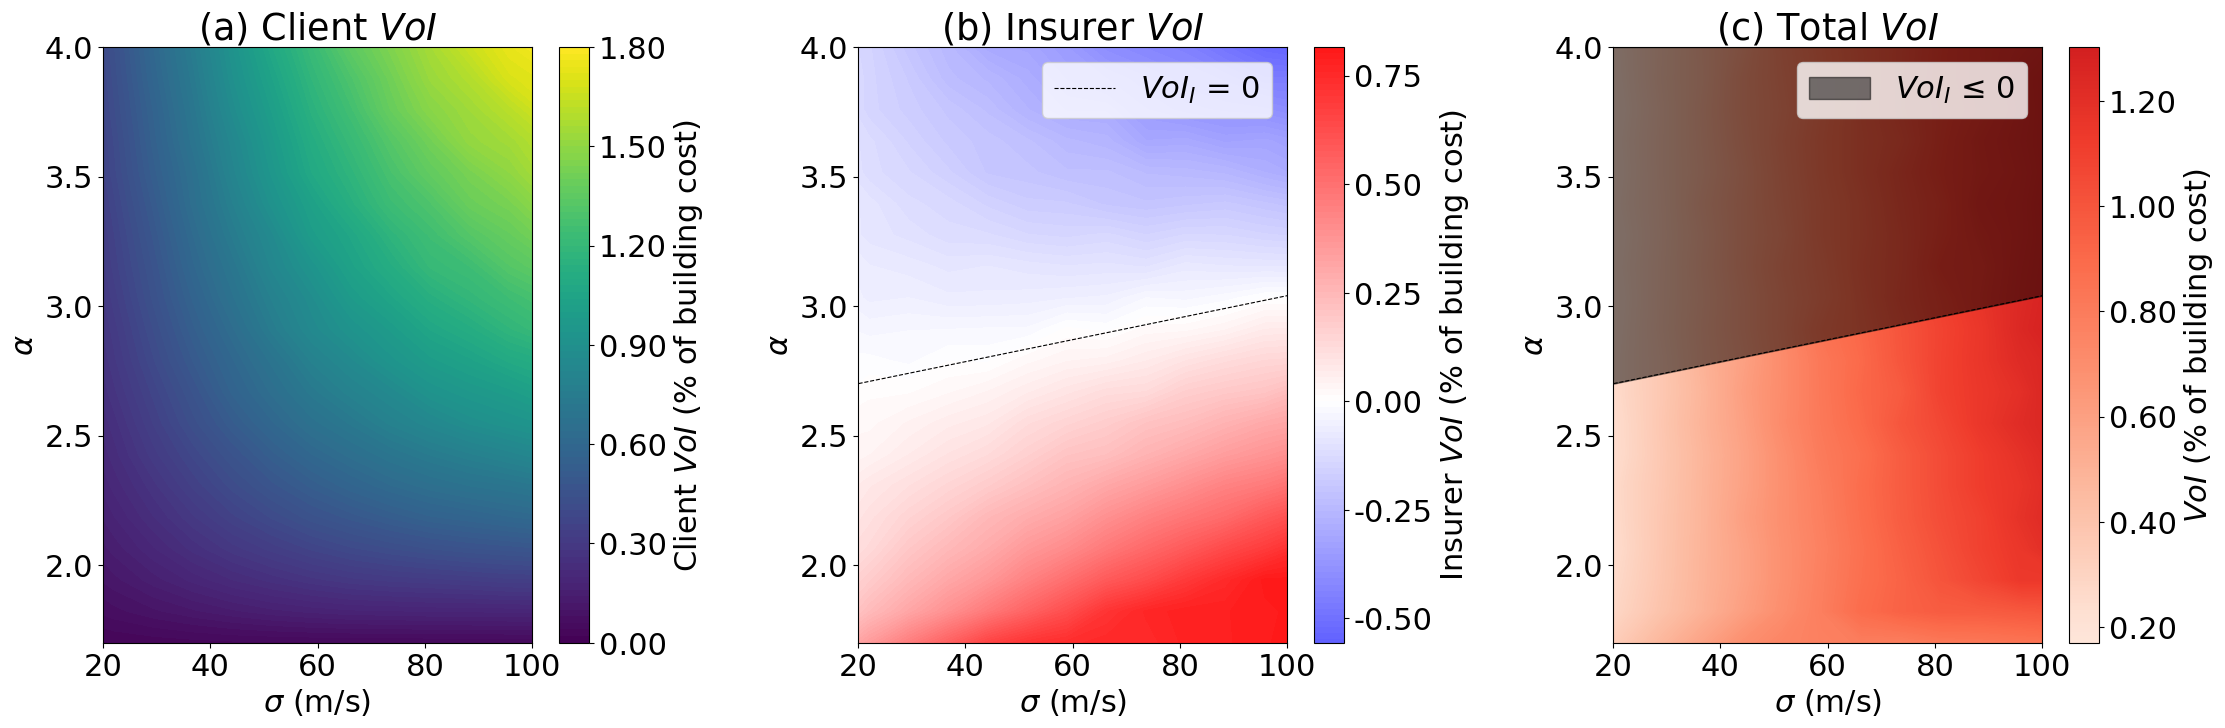

In [2]:
# ============================================================
# 1. SET PARAMETERS
# ============================================================

plt.rcParams.update({'font.size': 22})

alphas = np.linspace(1.7, 4, 20)
SD = np.linspace(0, 140, 20)

# Select the standard deviation range to plot
SD_filtered = SD[(SD >= 14) & (SD <= 110)]
SD_grid, alpha_grid = np.meshgrid(SD_filtered, alphas)

# Filter the matrices to match the selected standard deviations
mask = (SD >= 14) & (SD <= 110)
EVPI_matrix_filtered = EVPI_matrix[:, mask]
EVPI_profit_matrix_filtered = EVPI_profit_matrix[:, mask]

# Zero-VoI boundary for the insurer
zero_line = 3.04 + (SD_filtered - 100) * (34 / 8000)
y2 = np.full_like(SD_filtered, 4)

# Colour scale limits
vmax = EVPI_matrix_filtered.max()
vmin = -vmax

plt.figure(figsize=(23, 8))

# Contour plot for client EVPI
plt.subplot(1, 3, 1)
contour1 = plt.contourf(SD_grid, alpha_grid, EVPI_matrix_filtered, cmap='viridis', levels=100)
cbar = plt.colorbar(contour1, label=f'Client $VoI$ (% of building cost)')
cbar.locator = MaxNLocator(nbins=6)
cbar.update_ticks()
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

plt.title(f'(a) Client $VoI$')
plt.xlabel('$\sigma$ (m/s)')
plt.ylabel(r'$\alpha$')
plt.xlim(20, 100)

vmax = EVPI_matrix_filtered.max()
vmin = -vmax

# Contour plot for insurer EVPI
x = SD_filtered
y2 = np.ones_like(x) * 4  # Set y2 as a constant line at y = 4

plt.subplot(1, 3, 2)
plt.plot(x, zero_line, linewidth=0.8, linestyle='--', color='k', label=r'$VoI_{I}$ = 0')

contour2 = plt.contourf(SD_grid, alpha_grid, EVPI_profit_matrix_filtered, vmin=vmin, vmax=vmax, levels=790, cmap='seismic')
cbar = plt.colorbar(contour2, label=f'Insurer $VoI$ (% of building cost)')
cbar.locator = MaxNLocator(nbins=6)
cbar.update_ticks()
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

plt.xlim(20, 100)
plt.title(f'(b) Insurer $VoI$')
plt.xlabel('$\sigma$ (m/s)')
plt.legend()
plt.ylabel(r'$\alpha$')

# Contour plot for total VoI
plt.subplot(1, 3, 3)
plt.plot(x, zero_line, linewidth=0.8, linestyle='--', color='k')

total_VoI_filtered = EVPI_profit_matrix_filtered + EVPI_matrix_filtered
contour3 = plt.contourf(SD_grid, alpha_grid, total_VoI_filtered, vmin=0, vmax=vmax, levels=500, cmap='Reds')
cbar = plt.colorbar(contour3, label=f'$VoI$ (% of building cost)')
cbar.locator = MaxNLocator(nbins=6)
cbar.update_ticks()
cbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.2f}'))

plt.title(f'(c) Total $VoI$')
plt.xlabel('$\sigma$ (m/s)')
plt.ylabel(r'$\alpha$')

plt.fill_between(x, zero_line, y2, color='k', alpha=0.5, label=r'$VoI_{I}$ ≤ 0')
plt.legend()
plt.xlim(20, 100)

plt.tight_layout(pad=1.5)

plt.show()
